https://en.wikipedia.org/wiki/Degrees_of_freedom_(statistics)

https://sites.utexas.edu/sos/degreesfreedom/


The useful way to unify these two explanations is: **degrees of freedom (df) measure how many independent directions remain after constraints or fitting choices are accounted for.** “How many values are free to vary?” is a good first intuition; linear algebra makes it precise. The classroom analogy captures the idea, while the geometric view shows why df applies to regression and many statistical tests. <citation src="3,4"></citation>

### From a sample mean to regression

For \(n\) observations, the data vector \(\mathbf y\) starts with \(n\) coordinates. If you fix its sample mean, the deviations from that mean must sum to zero:

\[
\sum_{i=1}^{n}(y_i-\bar y)=0.
\]

That is one independent constraint, so the residual deviations have \(n-1\) degrees of freedom. For example, if three deviations sum to zero, choosing two determines the third. This is why the usual unbiased sample variance divides the squared deviations by \(n-1\), rather than \(n\).

In ordinary least squares, regression fits \(\mathbf y\) by projecting it onto the space spanned by the columns of the design matrix \(X\). If \(X\) has rank \(r\), the fitted values occupy \(r\) independent directions, and the residuals occupy the remaining \(n-r\):

\[
df_{\text{model}}=r,\qquad df_{\text{residual}}=n-r.
\]

With an intercept and \(p\) independent predictors, \(r=p+1\), so residual df is \(n-p-1\). The important quantity is **rank**, not simply the number of columns: duplicate or linearly dependent predictors do not add independent directions. In OLS, the hat matrix \(H=X(X^\top X)^{-1}X^\top\) projects onto the model space, and its trace is the model’s rank. <citation src="4,6"></citation>

### Why df matters in inference

Suppose the regression errors are independent, normally distributed, and have common variance \(\sigma^2\). In OLS, fitting the model imposes constraints on the residual vector; under those assumptions, the residual sum of squares divided by \(\sigma^2\) follows a chi-squared distribution with \(n-r\) degrees of freedom. That df is what makes the usual residual-variance estimate

\[
\hat{\sigma}^2=\frac{\sum_i (y_i-\hat y_i)^2}{n-r}
\]

unbiased under the model assumptions. It also determines the reference distributions used for tests and confidence intervals. More df often means more information, but df alone does not guarantee greater power: effect size, noise, design, and test choice matter too. <citation src="4,5"></citation>

### What changes with Ridge?

Ridge regression does not make a hard projection onto a fixed \(r\)-dimensional model space. It shrinks fitted values continuously, so the model’s **effective degrees of freedom** are generally fractional rather than a simple integer count.

For fixed \(X\), Ridge’s fitted values can be written \(\hat{\mathbf y}=H_\alpha\mathbf y\). A common effective model-df definition is \(\operatorname{tr}(H_\alpha)\): informally, it sums how responsive the fitted values are to changes in the observed outcomes. For centered predictors with an unpenalized intercept, this is

\[
df_{\text{Ridge}}
=1+\sum_j \frac{s_j^2}{s_j^2+\alpha},
\]

where \(s_j\) are the singular values of the centered design matrix and \(\alpha\) is scikit-learn Ridge’s penalty strength. Each direction contributes between 0 and 1: strong shrinkage contributes less; as \(\alpha\to0\), the contributions approach the OLS rank. This is **effective model df**, not automatically a universal residual-df formula for every inferential task. <citation src="4"></citation>

Here is a compact calculation with scikit-learn. It explicitly computes the effective df for Ridge with an intercept, using the same standardized predictor matrix the fitted model sees:

```python
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X, y = load_diabetes(return_X_y=True)
alpha = 10.0

model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=alpha),
)
model.fit(X, y)

# StandardScaler centers each feature; Ridge leaves the intercept unpenalized.
X_scaled = model.named_steps["standardscaler"].transform(X)
singular_values = np.linalg.svd(X_scaled, compute_uv=False)

df_model = 1 + np.sum(
    singular_values**2 / (singular_values**2 + alpha)
)

print(f"Effective model df: {df_model:.2f}")
print(f"n - effective model df: {len(y) - df_model:.2f}")
```

The final quantity is a useful rough complement to model df, but don’t automatically treat it as the exact residual df for a formal test. Effective-df definitions can depend on the smoother and the inferential goal. <citation src="4"></citation>

**Practical takeaway:** use \(n-\operatorname{rank}(X)\) for the residual df of classical OLS; use an effective-df idea for shrinkage or smoothing models; and check which df a particular test or estimator actually requires. Degrees of freedom are not just “sample size minus number of features”—they describe the independent information left for the specific calculation.

In [1]:
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X, y = load_diabetes(return_X_y=True)
alpha = 10.0

model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=alpha),
)
model.fit(X, y)

# StandardScaler centers each feature; Ridge leaves the intercept unpenalized.
X_scaled = model.named_steps["standardscaler"].transform(X)
singular_values = np.linalg.svd(X_scaled, compute_uv=False)

df_model = 1 + np.sum(singular_values**2 / (singular_values**2 + alpha))

print(f"Effective model df: {df_model:.2f}")
print(f"n - effective model df: {len(y) - df_model:.2f}")


Effective model df: 9.83
n - effective model df: 432.17


---

The page is mathematically sound overall, but its most important idea is deeper than “plot TPR against FPR”: **ROC evaluates the ranking induced by a score across every possible threshold.** It does not, by itself, say whether a particular threshold is useful in practice.

### A threshold turns scores into decisions

For a score \(s(x)\), predicting positive when \(s(x)\ge t\) gives:

\[
\mathrm{TPR}(t)=P(s\ge t\mid Y=1),\qquad
\mathrm{FPR}(t)=P(s\ge t\mid Y=0).
\]

Lowering \(t\) usually catches more actual positives, but also flags more negatives. Each threshold gives one operating point \((\mathrm{FPR},\mathrm{TPR})\); sweeping through thresholds traces the ROC curve. In scikit-learn, `roc_curve` returns thresholds in decreasing order, and its threshold convention is `score >= threshold`. The first threshold is \(+\infty\), representing the all-negative classifier at \((0,0)\). <citation src="3"></citation>

The exact equality convention matters when scores tie. The pasted formulas use \(s>t\), while scikit-learn uses \(s\ge t\); for continuous distributions that distinction has probability zero, but empirical model scores often have ties.

### What AUC actually means

AUC has a useful ranking interpretation:

\[
\mathrm{AUC}
=P(s(X^+)>s(X^-))
+\frac12P(s(X^+)=s(X^-)),
\]

where \(X^+\) and \(X^-\) are independently drawn positive and negative examples. So an AUC of \(0.90\) means a randomly chosen positive receives a higher score than a randomly chosen negative about 90% of the time, with ties counted half.

That explains both the strength and limitation of AUC:

- It measures **ranking**, not whether scores are calibrated probabilities. A model can rank cases well while its “0.8” scores are not actually right 80% of the time.
- Any strictly increasing transformation of the scores leaves the ranking—and thus AUC—unchanged.
- It summarizes performance over thresholds, but does not identify the best threshold for your application. AUC \(=0.5\) means chance-level ranking in aggregate; it does not mean the model’s output probabilities are calibrated or that every threshold behaves identically.

Scikit-learn can compute ROC AUC from either positive-class probabilities or unthresholded decision scores. <citation src="2"></citation>

### The normal example makes separation concrete

With negative scores \(N(0,1)\) and positive scores \(N(d',1)\),

\[
\mathrm{FPR}(t)=1-\Phi(t),\qquad
\mathrm{TPR}(t)=1-\Phi(t-d').
\]

Here \(d'\) is the difference between the class means in standard-deviation units. Because the difference \(S^+-S^-\) follows \(N(d',2)\),

\[
\mathrm{AUC}=P(S^+>S^-)=\Phi\!\left(\frac{d'}{\sqrt2}\right).
\]

For example, \(d'=2\) gives AUC \(\approx 0.921\). If \(d'=0\), the score distributions are identical and the population ROC is the diagonal. If \(d'<0\), the score tends to rank positives below negatives; reversing the score direction would produce AUC \(1-\mathrm{AUC}\). The formula in the page is correct under its equal-variance normal assumptions.

### Why a low FPR may still mean many false alarms

FPR is a **rate among negatives**, not a count and not the fraction of positive predictions that are correct. Suppose there are 100,000 negative cases and the FPR is 1%: that still produces 1,000 false positives. If there are only 1,000 positive cases and recall is 90%, there are 900 true positives, so precision is \(900/(900+1{,}000)\approx47\%\).

That is why ROC can be less informative when the positive class is rare or false positives are costly. A precision–recall curve, the expected number of false alarms, or performance at a constrained FPR may better reflect the actual use case. The right choice depends on deployment costs and prevalence—not just which curve looks better.

### A scikit-learn example

This uses the earlier breast-cancer convention, with malignant cases mapped to positive class `1`. The test set evaluates performance; it should not be used to tune the threshold.

```python
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X, y_original = load_breast_cancer(return_X_y=True)
y = 1 - y_original  # malignant becomes the positive class, 1

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=42,
)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2_000),
)
model.fit(X_train, y_train)

# Select the probability column corresponding to class 1 explicitly.
positive_col = np.flatnonzero(model.classes_ == 1)[0]
scores = model.predict_proba(X_test)[:, positive_col]

fpr, tpr, thresholds = roc_curve(y_test, scores, pos_label=1)
auc = roc_auc_score(y_test, scores)

print(f"Test ROC AUC: {auc:.3f}")
RocCurveDisplay.from_predictions(
    y_test,
    scores,
    name=f"Logistic regression (AUC = {auc:.3f})",
)
```

If you need a decision threshold, choose it on a validation set based on an explicit goal—for example, a minimum acceptable recall or a maximum tolerable FPR—then evaluate that chosen threshold once on untouched test data. The ROC curve is the trade-off map; the application’s costs determine which point to use.

Test ROC AUC: 0.996


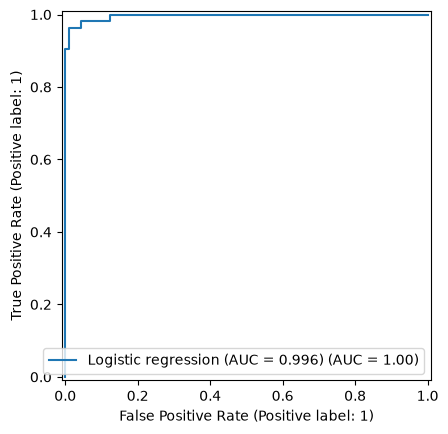

In [1]:
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X, y_original = load_breast_cancer(return_X_y=True)
y = 1 - y_original  # malignant becomes the positive class, 1

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=42,
)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2_000),
)
model.fit(X_train, y_train)

# Select the probability column corresponding to class 1 explicitly.
positive_col = np.flatnonzero(model.classes_ == 1)[0]
scores = model.predict_proba(X_test)[:, positive_col]

fpr, tpr, thresholds = roc_curve(y_test, scores, pos_label=1)
auc = roc_auc_score(y_test, scores)

print(f"Test ROC AUC: {auc:.3f}")
RocCurveDisplay.from_predictions(
    y_test,
    scores,
    name=f"Logistic regression (AUC = {auc:.3f})",
)
